# Beginner walkthrough: ARIMA vs SARIMA for daily wind speed (Chennai)

A **simplified, step-by-step** version of this repository's code (a reference implementation of my own paper, rebuilt in Python on synthetic data). It uses the **synthetic** daily series
`data/synthetic/synthetic_chennai_daily.csv`, so results are a demo only and **will differ from the paper's published results**.

Steps: 1) load · 2) look at the data · 3) ADF stationarity test · 4) split · 5) fit ARIMA(3,0,2) and SARIMA(0,1,2)(0,1,2,4) · 6) MSE / RMSE / MAE / MAPE / R² · 7) plot.

Requirements: `numpy pandas statsmodels matplotlib`.

## 1. Load the data
Local file first (repo root or `notebooks/`), then download from GitHub (e.g. Colab), otherwise generate it inline.

In [1]:
import os, urllib.request
from pathlib import Path
import numpy as np, pandas as pd

FILE = "synthetic_chennai_daily.csv"
RAW_URL = "https://raw.githubusercontent.com/Rishabh-bgp/arima-sarima-wind-speed-chennai/main/data/synthetic/" + FILE

def find_local():
    # works whether the notebook is started from the repo root or from notebooks/
    for base in (Path.cwd(), Path.cwd().parent):
        p = base / "data" / "synthetic" / FILE
        if p.exists():
            return p
    return None

local = find_local()
if local is not None:
    df = pd.read_csv(local); print("Loaded local file:", local)
else:
    try:  # e.g. on Google Colab
        df = pd.read_csv(RAW_URL); print("Downloaded:", RAW_URL)
    except Exception as e:
        print("Download failed (", e, ") -> generating synthetic data inline")
        df = None

if df is None:
    rng = np.random.default_rng(42)
    idx = pd.date_range("2015-01-01", "2017-12-31", freq="D"); doy = idx.dayofyear.values
    seas = 1.3*np.exp(-((doy-190)/45)**2) + 0.6*np.exp(-((doy-340)/25)**2)
    noise = np.zeros(len(idx)); e = rng.normal(0, 0.55, len(idx))
    for t in range(1, len(idx)): noise[t] = 0.6*noise[t-1] + e[t]
    df = pd.DataFrame({"date": idx, "wind_speed": np.clip(3.0+seas+noise, 0.2, None)})
s = df.assign(date=pd.to_datetime(df["date"])).set_index("date")["wind_speed"].asfreq("D").interpolate()
s.describe()

Loaded local file: /workspace/repos/arima-sarima-wind-speed-chennai/data/synthetic/synthetic_chennai_daily.csv


count    1096.000000
mean        3.315214
std         0.801257
min         0.790000
25%         2.762000
50%         3.287000
75%         3.818000
max         5.721000
Name: wind_speed, dtype: float64

## 2. Look at the data

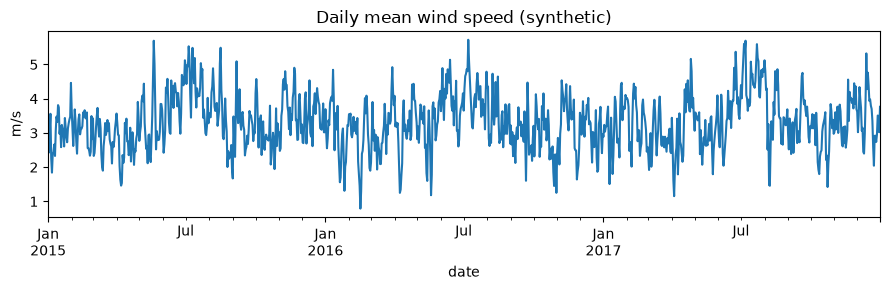

In [2]:
import matplotlib.pyplot as plt
s.plot(figsize=(9, 3), title="Daily mean wind speed (synthetic)"); plt.ylabel("m/s"); plt.tight_layout(); plt.show()

## 3. Is the series stationary? (Augmented Dickey–Fuller)
p-value < 0.05 → we reject the unit-root hypothesis, i.e. the series looks stationary (so d = 0 is reasonable for ARIMA).

In [3]:
import warnings; warnings.filterwarnings("ignore")
from statsmodels.tsa.stattools import adfuller
stat, p, *_ = adfuller(s.values, autolag="AIC")
print(f"ADF statistic {stat:.3f}, p-value {p:.4f}")

ADF statistic -7.841, p-value 0.0000


## 4. Train / test split
As in the paper's code: hold out the **last 30 days** for testing.

In [4]:
train, test = s.iloc[:-30], s.iloc[-30:]
print(len(train), "train days,", len(test), "test days")

1066 train days, 30 test days


## 5. Fit ARIMA(3,0,2) and SARIMA(0,1,2)(0,1,2,4)
* **ARIMA(p,d,q)**: p autoregressive terms, d differences, q moving-average terms.
* **SARIMA** adds a seasonal part (P,D,Q,s) with season length s = 4, as in the paper.

In [5]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
arima = ARIMA(train.values, order=(3, 0, 2)).fit()
sarima = SARIMAX(train.values, order=(0, 1, 2), seasonal_order=(0, 1, 2, 4)).fit(disp=False)
pa = arima.predict(start=len(train), end=len(train)+len(test)-1)
ps = sarima.predict(start=len(train), end=len(train)+len(test)-1)
print("ARIMA AIC", round(arima.aic, 1), "| SARIMA AIC", round(sarima.aic, 1))

/workspace/venv/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/workspace/venv/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


/workspace/venv/lib/python3.13/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


ARIMA AIC 1762.6 | SARIMA AIC 1846.1


## 6. Errors
The paper compares **MSE** and **RMSE**; we also show MAE, MAPE and R², plus a **persistence** baseline (every test day = the last training day). Reported as they come out.

In [6]:
def report(name, y, p):
    e = y - p; mse = np.mean(e**2)
    print(f"{name:28s} MSE {mse:.4f} RMSE {np.sqrt(mse):.4f} MAE {np.mean(np.abs(e)):.4f} "
          f"MAPE {np.mean(np.abs(e/y))*100:.1f}% R2 {1-np.sum(e**2)/np.sum((y-y.mean())**2):.3f}")
report("ARIMA(3,0,2)", test.values, pa)
report("SARIMA(0,1,2)(0,1,2,4)", test.values, ps)
report("Persistence (last train day)", test.values, np.repeat(train.values[-1], len(test)))
print("Short demo on SYNTHETIC data - not comparable with the paper's published results.")

ARIMA(3,0,2)                 MSE 0.5228 RMSE 0.7231 MAE 0.5959 MAPE 18.3% R2 0.018
SARIMA(0,1,2)(0,1,2,4)       MSE 0.7176 RMSE 0.8471 MAE 0.6873 MAPE 23.1% R2 -0.348
Persistence (last train day) MSE 0.5555 RMSE 0.7453 MAE 0.6100 MAPE 19.5% R2 -0.043
Short demo on SYNTHETIC data - not comparable with the paper's published results.


## 7. Plot

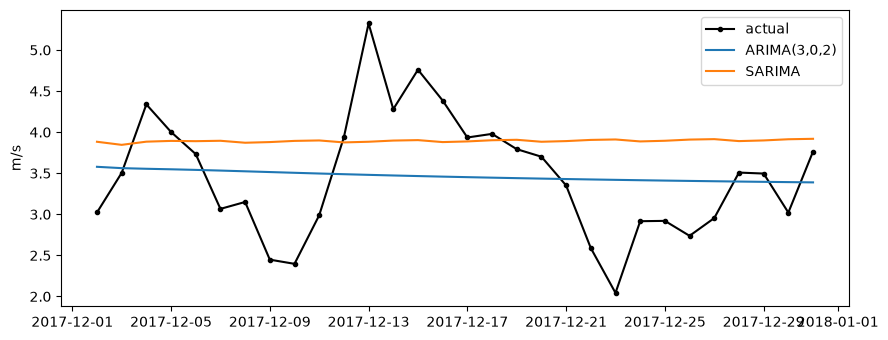

In [7]:
plt.figure(figsize=(9, 3.5))
plt.plot(test.index, test.values, "k-o", ms=3, label="actual")
plt.plot(test.index, pa, label="ARIMA(3,0,2)"); plt.plot(test.index, ps, label="SARIMA")
plt.ylabel("m/s"); plt.legend(); plt.tight_layout(); plt.show()

## Next steps
`python train.py` runs both tests (last 30 days and 80:20) plus an AIC order search. See the README **Data** section to use NASA POWER or your own CSV.